# Weather forecasts and finalized NYC electricity prices
## tl;dr
**The validation-selected spline temperature model reduced 2025 MAE by 16.6% versus calendar alone**: $35.16/MWh to $29.33/MWh across 362 matched target days. It improved MAE in 10 of 12 months.

The seven-day paired block-bootstrap 95% interval for calendar-minus-selected-weather MAE is **$1.98 to $9.82/MWh**. The primary paired block interval remains above zero.

This is retrospective **prediction research for finalized day-ahead prices using dated operational forecasts**. A price-history baseline and trading profitability remain untested. The 2025 demand period and two feasibility price samples had already been inspected; 2025 price outcomes were excluded from model fitting and selection but are not described as wholly unseen.

## Context & Methods
At **04:00 New York time on D−1**, predict the NYC/Zone J day-ahead LBMP for **18:00–19:00 on D**, in $/MWh. Delivery is normally 38 hours ahead, or 37/39 at DST. The auction price is usually published on D−1, before physical delivery; this is a different horizon from time until price revelation.

The question is narrowly whether forecast temperature adds information beyond the specified calendar baseline. No historical-price or load inputs are included, so unavailable corrections cannot leak through those covariates. Outcomes are corrected/latest archived prices, called finalized prices in this study; they are not verified original auction publications or immutable settlement records.

### Key Assumptions
- The retained NOAA HRRR operational 06 UTC forecast object's Last-Modified predates cutoff by at least five minutes. It is archive-availability evidence, not an exact first-NCEP-publication ledger. Multipart objects and late/replaced files are excluded.
- The forecast is genuinely a 40/41-hour forecast valid at the target time, not an analysis or realized future observation. Embedded issue/valid times, field identity, operational status and byte receipts are checked.
- A grid point near LaGuardia proxies city weather; regional weather, fuel prices, supply outages, congestion and other price drivers are omitted.
- Corrected historical prices are outcome labels only. Retrospectively corrected fitting labels mean this is not a complete as-of simulation of historical model training.
- Missing/late-forecast dates are excluded equally across models, potentially selecting easier or harder dates. No late issue or realized weather is substituted.

Fit 2021–2023; choose the weather specification on 2024 MAE; refit on 2021–2024; evaluate 2025. All models have the same 14 calendar columns: weekday, three annual Fourier harmonics and a fixed federal-holiday proxy excluding Juneteenth. Ordinary least squares compares calendar-only, linear forecast temperature, and a three-hinge piecewise-linear forecast-temperature spline. Center/scale/knots use fitting data only. See [EXPERIMENT.md](EXPERIMENT.md) for the frozen choices.

### 1. Reproduce the frozen calculation

In [1]:
from pathlib import Path
import sys, json, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
ROOT = Path.cwd()
assert (ROOT / 'EXPERIMENT.md').exists(), 'Execute from price_research.'
sys.path.insert(0, str(ROOT / 'src'))
from run import main
with contextlib.redirect_stdout(io.StringIO()):
    main()  # Refit and evaluate the same frozen choices from source-verified daily data.
OUT = ROOT / 'outputs'
summary = json.loads((OUT / 'summary.json').read_text())
configuration = json.loads((OUT / 'selected_configuration.json').read_text())
selected = summary['selected_weather_model']
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'axes.axisbelow': True,
                     'savefig.dpi': 150})
COLORS = {'calendar': '#52616b', 'linear': '#b5791b', 'spline': '#2166ac'}
LABELS = {'calendar': 'Calendar only', 'linear': '+ Linear forecast temperature',
          'spline': '+ Forecast-temperature spline'}
def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(OUT / filename, bbox_inches='tight')
    plt.show()
print('Frozen price comparison reproduced; no realized weather, price history, load or demand-model inputs.')

Matplotlib is building the font cache; this may take a moment.


Frozen price comparison reproduced; no realized weather, price history, load or demand-model inputs.


## Data
[NOAA's operational HRRR archive](https://registry.opendata.aws/noaa-hrrr-pds/) supplies the fixed 06 UTC cycle and target-valid 2m temperature forecast. Only the relevant GRIB message is downloaded using byte ranges. ecCodes extracts the nearest point to LaGuardia and verifies forecast metadata. [NYISO's historical day-ahead archive](https://mis.nyiso.com/public/P-2Alist.htm) supplies corrected outcome prices. [SOURCES.md](SOURCES.md) documents the timing evidence and its limits.

In [2]:
data = pd.read_csv(OUT / 'daily_data.csv')
coverage = pd.read_csv(OUT / 'annual_coverage.csv')
exclusions = pd.read_csv(OUT / 'excluded_days.csv')
display(coverage.assign(coverage_pct=coverage.coverage * 100).drop(columns='coverage').round(2))
print(f"Matched {data.usable.sum():,} of {len(data):,} target days; {len(exclusions)} excluded.")
display(exclusions.reason.value_counts().rename('Excluded days').to_frame())
points = json.loads((OUT / 'grid_points.json').read_text())
print('Nearest grid metadata:', {grid: {k:v for k,v in point.items() if k != 'value'} for grid, point in points.items()})
assert (pd.to_datetime(data.loc[data.usable, 'archive_available_utc'], utc=True)
        <= pd.to_datetime(data.loc[data.usable, 'cutoff_utc'], utc=True) - pd.Timedelta(minutes=5)).all()
print('Every included forecast has a retained archive-availability witness before the cutoff buffer.')

,year,expected_days,usable_days,coverage_pct
0,2021,365,360,98.63
1,2022,365,359,98.36
2,2023,365,364,99.73
3,2024,366,364,99.45
4,2025,365,362,99.18


Matched 1,809 of 1,826 target days; 17 excluded.


,Excluded days
reason,
Archive object unavailable at cutoff minus five minutes,11
Multipart timestamp does not prove completed availability,6


Nearest grid metadata: {'78367561440d7c7b608b8532a02e4780': {'lat': 40.77479231172039, 'lon': 286.10350969901543, 'distance': 1.456423357277297, 'index': 1257257}}
Every included forecast has a retained archive-availability witness before the cutoff buffer.


The coverage table's denominator is all expected delivery dates, not only dates with successful downloads. Each exclusion is retained. Eight feasibility source samples were reused with original receipts; all dates pass the same gate. The study uses one daily target hour, not thousands of independent hourly experiments.

## Results
### 2. Validation selection and final error comparison

,model,days,mae_mwh,rmse_mwh,mean_residual_mwh
0,calendar,364,28.808,35.764,-16.598
1,linear,364,28.395,34.979,-16.722
2,spline,364,20.323,25.968,-14.292


Weather model selected using 2024 MAE: spline


,days,mae_mwh,rmse_mwh,mean_residual_mwh,improvement_pct
model,,,,,
calendar,362,35.158,62.302,27.419,0.000
linear,362,35.857,61.587,26.407,-1.989
spline,362,29.333,49.458,21.806,16.569


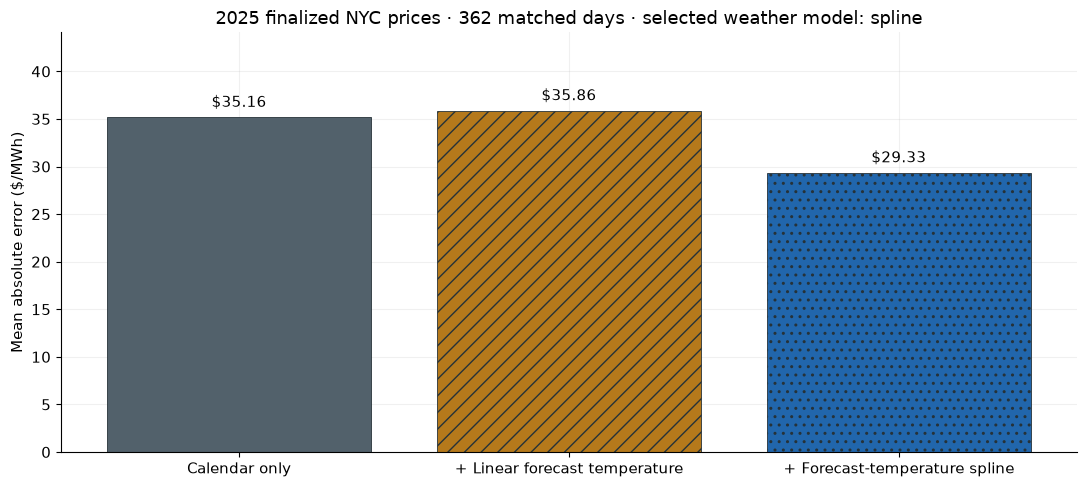

In [3]:
display(pd.read_csv(OUT / 'validation_metrics.csv').round(3))
print('Weather model selected using 2024 MAE:', selected)
scores = pd.read_csv(OUT / 'test_metrics.csv')
overall = scores.loc[scores.group_type.eq('overall')].set_index('model').loc[list(LABELS)]
display(overall[['days', 'mae_mwh', 'rmse_mwh', 'mean_residual_mwh', 'improvement_pct']].round(3))
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar([LABELS[name] for name in LABELS], overall.mae_mwh,
              color=[COLORS[name] for name in LABELS], hatch=['', '//', '..'],
              edgecolor='#263238', linewidth=.6)
ax.bar_label(bars, fmt='$%.2f', padding=5)
ax.set(ylabel='Mean absolute error ($/MWh)',
       title=f"2025 finalized NYC prices · {summary['matched_2025_days']} matched days · selected weather model: {selected}",
       ylim=(0, overall.mae_mwh.max() * 1.23))
save_figure(fig, '01_model_error_comparison.png')

The primary weather comparison is **spline**, chosen before scoring 2025. Both predefined weather variants are shown for transparency; we do not change the primary model to whichever wins in 2025. A calendar baseline is deliberately limited: this test does not establish incremental value over price-history/calendar or commercial energy forecasts. The selected model still underestimates finalized prices by **$21.81/MWh on average**, with **$49.46/MWh RMSE**; these are substantial remaining errors.

### 3. Finalized outcomes and estimates over the evaluation year

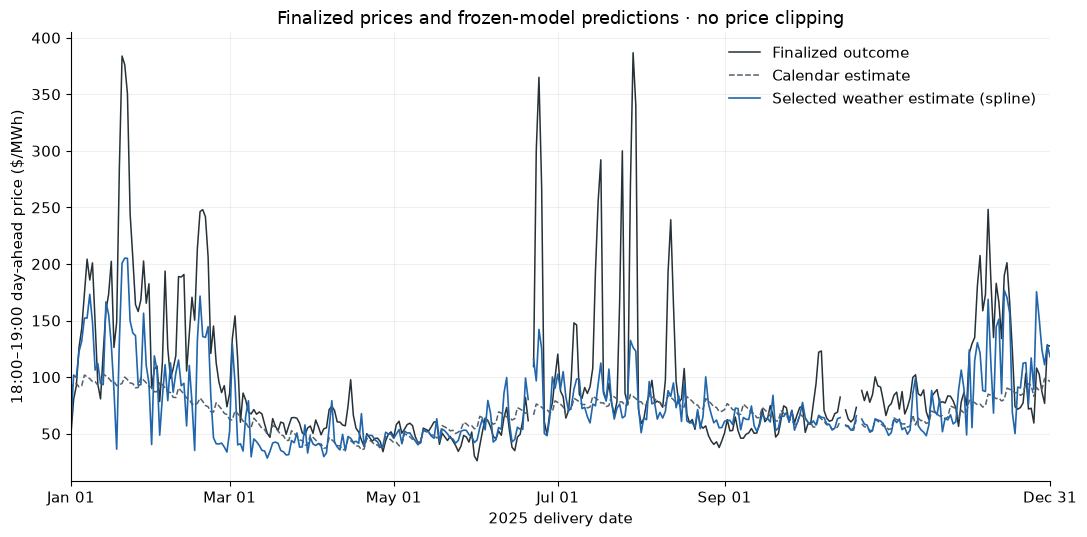

In [4]:
predictions = pd.read_csv(OUT / 'test_predictions.csv', parse_dates=['delivery_date'])
# Reindex to all calendar dates so missing forecasts leave gaps in the plotted lines.
plot = predictions.set_index('delivery_date').reindex(pd.date_range('2025-01-01', '2025-12-31'))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(plot.index, plot.finalized_price_mwh, color='#263238', linewidth=1.1, label='Finalized outcome')
ax.plot(plot.index, plot.calendar, color=COLORS['calendar'], linestyle='--', linewidth=1.1, label='Calendar estimate')
ax.plot(plot.index, plot[selected], color=COLORS[selected], linewidth=1.2, label=f'Selected weather estimate ({selected})')
ax.set(ylabel='18:00–19:00 day-ahead price ($/MWh)', xlabel='2025 delivery date',
       title='Finalized prices and frozen-model predictions · no price clipping')
ax.set_xticks(pd.to_datetime(['2025-01-01','2025-03-01','2025-05-01','2025-07-01','2025-09-01','2025-12-31']))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-12-31'))
ax.legend(frameon=False, loc='upper right')
save_figure(fig, '02_evaluation_year.png')

All matched outcomes remain in the evaluation, including negative values and price spikes. Missing-forecast dates are gaps, not zeros. A forecast of the finalized price level is not a trading return or an executable entry/exit price.

### 4. Monthly stability and dependence-aware uncertainty

model,calendar,linear,spline,selected_improvement_mwh,selected_improvement_pct
group,,,,,
1,86.014,81.564,56.862,29.152,33.892
2,66.141,63.976,58.683,7.458,11.276
3,15.795,18.419,24.035,-8.240,-52.164
4,14.504,15.246,13.657,0.847,5.837
5,9.339,13.708,5.445,3.894,41.697
6,37.999,43.945,29.360,8.639,22.734
7,62.835,65.509,57.262,5.574,8.870
8,26.019,28.536,22.522,3.497,13.441
9,11.721,14.833,7.558,4.163,35.516


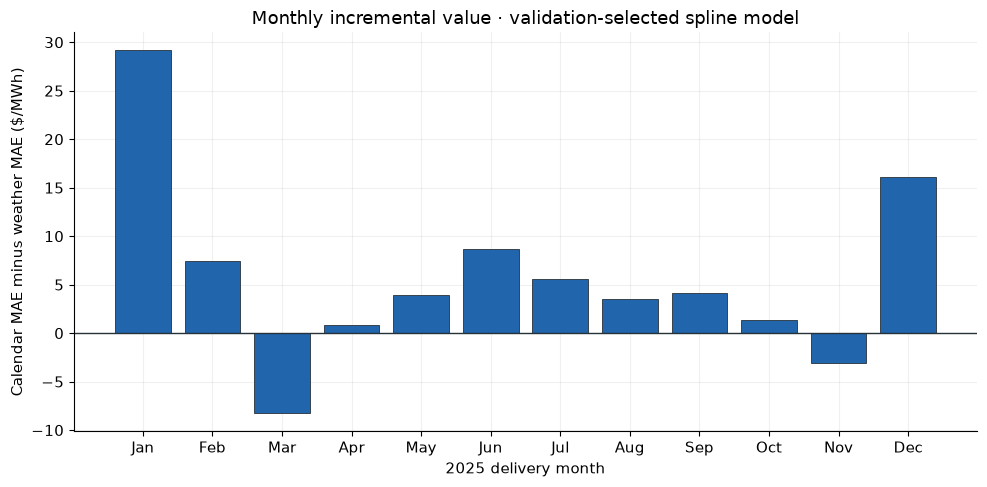

,weather_model,block_days,improvement_mwh,lower_95_mwh,upper_95_mwh,expected_calendar_days,paired_days
0,linear,7,-0.699,-1.899,0.519,365,362
1,linear,14,-0.699,-2.191,0.754,365,362
2,linear,28,-0.699,-2.494,1.187,365,362
3,spline,7,5.825,1.982,9.816,365,362
4,spline,14,5.825,1.649,10.388,365,362
5,spline,28,5.825,1.497,10.648,365,362


,model,lag_days,correlation,paired_days
0,calendar,1,0.757,358
1,calendar,7,0.163,352
2,linear,1,0.751,358
3,linear,7,0.142,352
4,spline,1,0.685,358
5,spline,7,0.144,352


In [5]:
monthly = scores.loc[scores.group_type.eq('month')].pivot(index='group', columns='model', values='mae_mwh')
monthly.index = monthly.index.astype(int)
monthly = monthly.sort_index()
monthly['selected_improvement_mwh'] = monthly.calendar - monthly[selected]
monthly['selected_improvement_pct'] = 100 * monthly.selected_improvement_mwh / monthly.calendar
display(monthly.round(3))
fig, ax = plt.subplots()
labels = [pd.Timestamp(2025, month, 1).strftime('%b') for month in monthly.index]
values = monthly.selected_improvement_mwh
bars = ax.bar(labels, values, color=COLORS[selected], edgecolor='#263238', linewidth=.6)
ax.axhline(0, color='#263238', linewidth=1)
ax.set(ylabel='Calendar MAE minus weather MAE ($/MWh)', xlabel='2025 delivery month',
       title=f'Monthly incremental value · validation-selected {selected} model')
save_figure(fig, '03_monthly_improvement.png')
display(pd.read_csv(OUT / 'uncertainty.csv').round(3))
display(pd.read_csv(OUT / 'residual_diagnostics.csv').round(3))

Positive monthly bars mean lower weather-model error; negative bars mean deterioration. **10 of twelve months improve.** The seven-day paired block interval for the selected comparison is $1.98–$9.82/MWh. The primary paired block interval remains above zero. Fourteen- and 28-day sensitivity intervals are reported without selecting the most favorable one. These intervals describe this one year's paired errors, not all future years or causal effects.

### 5. Adjusted association with forecast temperature

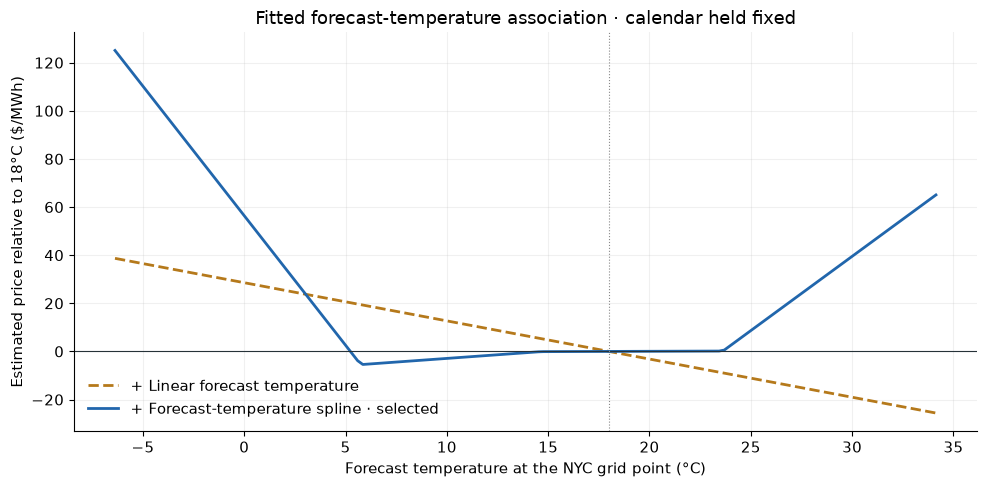

Curve restricted to fitting-sample 1st–99th percentiles: -6.4–34.1°C.


In [6]:
curve = pd.read_csv(OUT / 'forecast_temperature_response.csv')
fig, ax = plt.subplots()
for name, style in [('linear', '--'), ('spline', '-')]:
    ax.plot(curve.forecast_temperature_c, curve[name + '_relative_mwh'],
            label=LABELS[name] + (' · selected' if name == selected else ''),
            color=COLORS[name], linestyle=style, linewidth=2)
ax.axhline(0, color='#263238', linewidth=.8)
ax.axvline(18, color='#888888', linewidth=.8, linestyle=':')
ax.set(xlabel='Forecast temperature at the NYC grid point (°C)',
       ylabel='Estimated price relative to 18°C ($/MWh)',
       title='Fitted forecast-temperature association · calendar held fixed')
ax.legend(frameon=False)
save_figure(fig, '04_forecast_temperature_response.png')
print(f"Curve restricted to fitting-sample 1st–99th percentiles: {curve.forecast_temperature_c.min():.1f}–{curve.forecast_temperature_c.max():.1f}°C.")

This curve is a model association with **forecast**, not realized, temperature. It is not a causal temperature-to-price estimate or a climate scenario. Calendar is held fixed, and the model assumes an additive temperature response; other weather and market drivers are omitted.

### 6. Hot forecasts, large errors and gain concentration

In [7]:
display(scores.loc[scores.group_type.eq('forecast_temperature') & scores.group.eq('hot'),
                   ['model', 'days', 'mae_mwh', 'rmse_mwh', 'mean_residual_mwh', 'improvement_pct']].round(3))
print(f"Hot cutoff fixed from 2021–2023 forecast temperatures: {configuration['hot_forecast_threshold_c_2021_2023']:.2f}°C.")
concentration = json.loads((OUT / 'gain_concentration.json').read_text())
print('Gain concentration diagnostic:', concentration)
display(pd.read_csv(OUT / 'ten_largest_baseline_errors.csv')[
    ['delivery_date', 'finalized_price_mwh', 'baseline_absolute_error', 'selected_absolute_error', 'selected_error_improvement']].round(3))

,model,days,mae_mwh,rmse_mwh,mean_residual_mwh,improvement_pct
3,calendar,16,106.098,152.402,106.098,0.000
4,linear,16,115.750,160.437,115.750,-9.097
5,spline,16,84.909,122.801,69.708,19.971


Hot cutoff fixed from 2021–2023 forecast temperatures: 30.41°C.
Gain concentration diagnostic: {'total_absolute_error_improvement': 2108.8248408073987, 'ten_largest_baseline_error_days_improvement': 564.0744474432646, 'ten_day_share_of_total_improvement': 0.26748283523979133, 'diagnostic_only': 'Primary evaluation includes every matched day; no outlier deletion or model changes.'}


,delivery_date,finalized_price_mwh,baseline_absolute_error,selected_absolute_error,selected_error_improvement
0,2025-07-29,386.73,303.760,260.559,43.201
1,2025-06-24,365.00,290.064,222.834,67.230
2,2025-01-20,383.81,289.270,183.097,106.173
3,2025-01-21,376.12,276.114,170.932,105.182
4,2025-07-30,340.51,259.444,217.633,41.811
5,2025-01-22,350.80,252.992,145.812,107.180
6,2025-06-23,300.20,223.962,203.515,20.447
7,2025-07-25,300.00,221.995,236.105,-14.111
8,2025-07-17,292.09,214.887,179.658,35.229
9,2025-06-25,268.15,194.717,142.983,51.734


The selected model worsens MAE in **March and November**, and in the spring aggregate. Its one-day residual correlation remains **0.685**. The ten largest baseline-error days account for **26.7% of the net absolute-error improvement**; they contribute materially but do not account for the whole gain. Hot-forecast results cover only **16 evaluation days**, so they provide limited evidence about extreme conditions.

Hot conditions and largest-error tables are descriptive diagnostics. No hot-day cutoff or outlier rule was chosen using 2025 errors. The ten large-error days remain in the primary result. A gain dominated by a handful of events would limit the generalization even if overall MAE improves.

## Takeaways
The evaluated claim is strictly **incremental predictive value of dated forecast temperature over this calendar-only baseline for finalized NYC day-ahead prices**. Report the observed improvement or deterioration, its monthly stability and uncertainty without expanding the claim.

A strong price-history baseline remains untested. Weather may already be incorporated into auction participants' expectations; predictable price levels do not automatically identify mispricing. Supply, gas costs, regional weather, congestion and other drivers are omitted. One final year and selectively missing forecast dates limit generalization. Corrected historical outcome labels and archive timestamp evidence do not constitute a full historical execution simulation.

**No trading profitability, executable strategy, or causal price-impact claim is made.** No further model search or trading backtest is pending. The original demand study and the earlier stricter feasibility assessment remain separate records.

Reproduction from this folder: install `requirements.txt`; `python src/acquire.py` (network, cached files reused); `python src/prepare.py` (offline decoder and source gate); `python src/run.py`; `python -m unittest discover -s tests -v`; `python execute_notebook.py`. The executed notebook reruns fitting and scoring from the verified daily table; run preparation to regenerate that table from raw source messages.